In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",100)

Random_state=43

import warnings
warnings.filterwarnings("ignore")

In [13]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv('../data/test.csv')
print(train.shape)
print(test.shape)

(691369, 14)
(296302, 13)


In [14]:
train.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [15]:
test.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
0,691369,30.0,9.34,NaN,0.77,4.09,7.15,153.0,16.0,NaN,Other,Medium,Yes
1,691370,NaN,NaN,1.91,NaN,1.20,8.67,239.0,148.0,10.68,Female,High,No
2,691371,26.0,8.48,3.64,NaN,3.39,7.47,106.0,123.0,NaN,Male,NaN,No
3,691372,20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,Male,High,Yes
4,691373,25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,Male,Low,No


In [16]:
target = "addicted_label"
id_col="id"
X=train.drop(columns=[target])
y=train[target]

In [18]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()

categorical_cols = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols.remove(target)

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['id', 'age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']

Categorical columns:
['gender', 'stress_level', 'academic_work_impact']


In [19]:
missing = pd.DataFrame({
    "missing_value":train.isnull().sum(),
    "missing_percentage":train.isnull().mean()*100
})
missing=missing.sort_values("missing_percentage",ascending=False)
missing

,missing_value,missing_percentage
social_media_hours,133995,19.381112
gaming_hours,126821,18.343461
weekend_screen_time,112063,16.208855
daily_screen_time_hours,95854,13.864376
app_opens_per_day,80710,11.673940
notifications_per_day,67584,9.775388
stress_level,55148,7.976638
work_study_hours,51518,7.451592
sleep_hours,44480,6.433612
academic_work_impact,44224,6.396584


In [20]:
print(train.duplicated().sum())

0


In [22]:
target_count = train[target].value_counts()
target_percentage = (train[target].value_counts(normalize=True)*100)
target_summary=pd.DataFrame({
    "count":target_count,
    "percentage":target_percentage
})
target_summary

,count,percentage
addicted_label,,
1,490474,70.942435
0,200895,29.057565


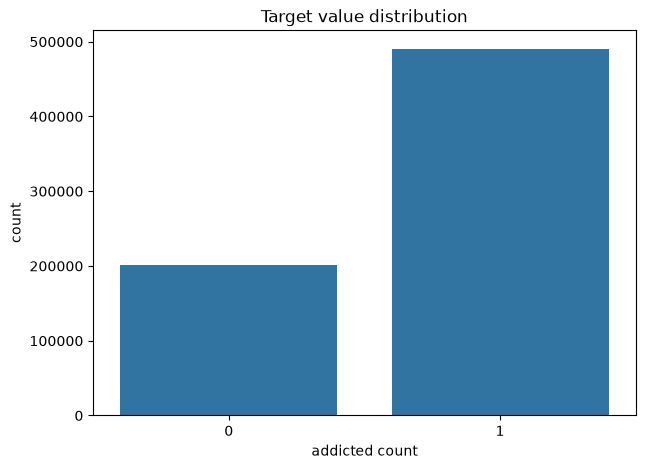

In [23]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=train,
    x=target
)
plt.title("Target value distribution")
plt.xlabel("addicted count")
plt.ylabel("count")
plt.show()

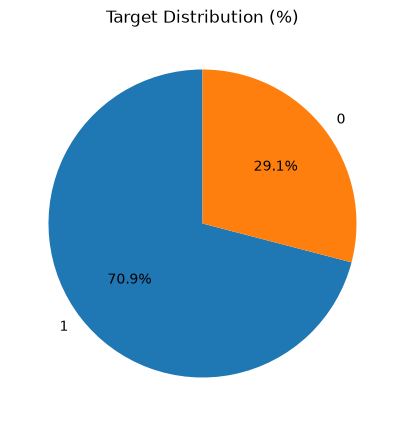

In [25]:
plt.figure(figsize=(7, 5))

train[target].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Target Distribution (%)")
plt.ylabel("")

plt.show()